COMPREHENSIVE MODEL COMPARISON WITH ALL METRICS

Configuration:
  - Training windows: 200
  - Testing windows: 50
  - Window size: 7 jobs
  - Output directory: model_comparison_20260306_032808

Loading data...
Dataset shape: (400000, 6)
Columns: ['Job_ID', 'Arrival_Time', 'Service_Time', 'Deadline_Exp', 'Deadline_Uni', 'Deadline_Erl']

Step 1: Generating 200 training windows...


Generating training data: 100%|██████████| 200/200 [00:08<00:00, 24.45it/s]



Training data shape: (200, 12)
Target distribution:
target_tq
1.5      2
2.0      2
5.0    196
Name: count, dtype: int64

Step 2: Training 63 ML Models...


Training models:  22%|██▏       | 14/63 [00:28<00:20,  2.41it/s]


⚠️  Error with SGD Regressor: Mean Tweedie deviance error with power=1 can only 


...

Training models: 100%|██████████| 63/63 [00:40<00:00,  1.57it/s]



Top 5 Models by R² Score:
      Model  R2         RMSE          MAE         MAPE
Extra Trees 1.0 0.000000e+00 0.000000e+00 0.000000e+00
   AdaBoost 1.0 0.000000e+00 0.000000e+00 0.000000e+00
   GP (RBF) 1.0 1.064790e-09 6.411590e-10 1.541397e-10
  Radius NN 1.0 0.000000e+00 0.000000e+00 0.000000e+00
    GP (RQ) 1.0 2.307403e-10 6.612738e-11 2.559603e-11

Step 3: Testing 59 models on 50 windows...


Testing windows: 100%|██████████| 50/50 [00:08<00:00,  5.76it/s]



Step 4: Creating comprehensive visualizations...


IndexError: positional indexers are out-of-bounds

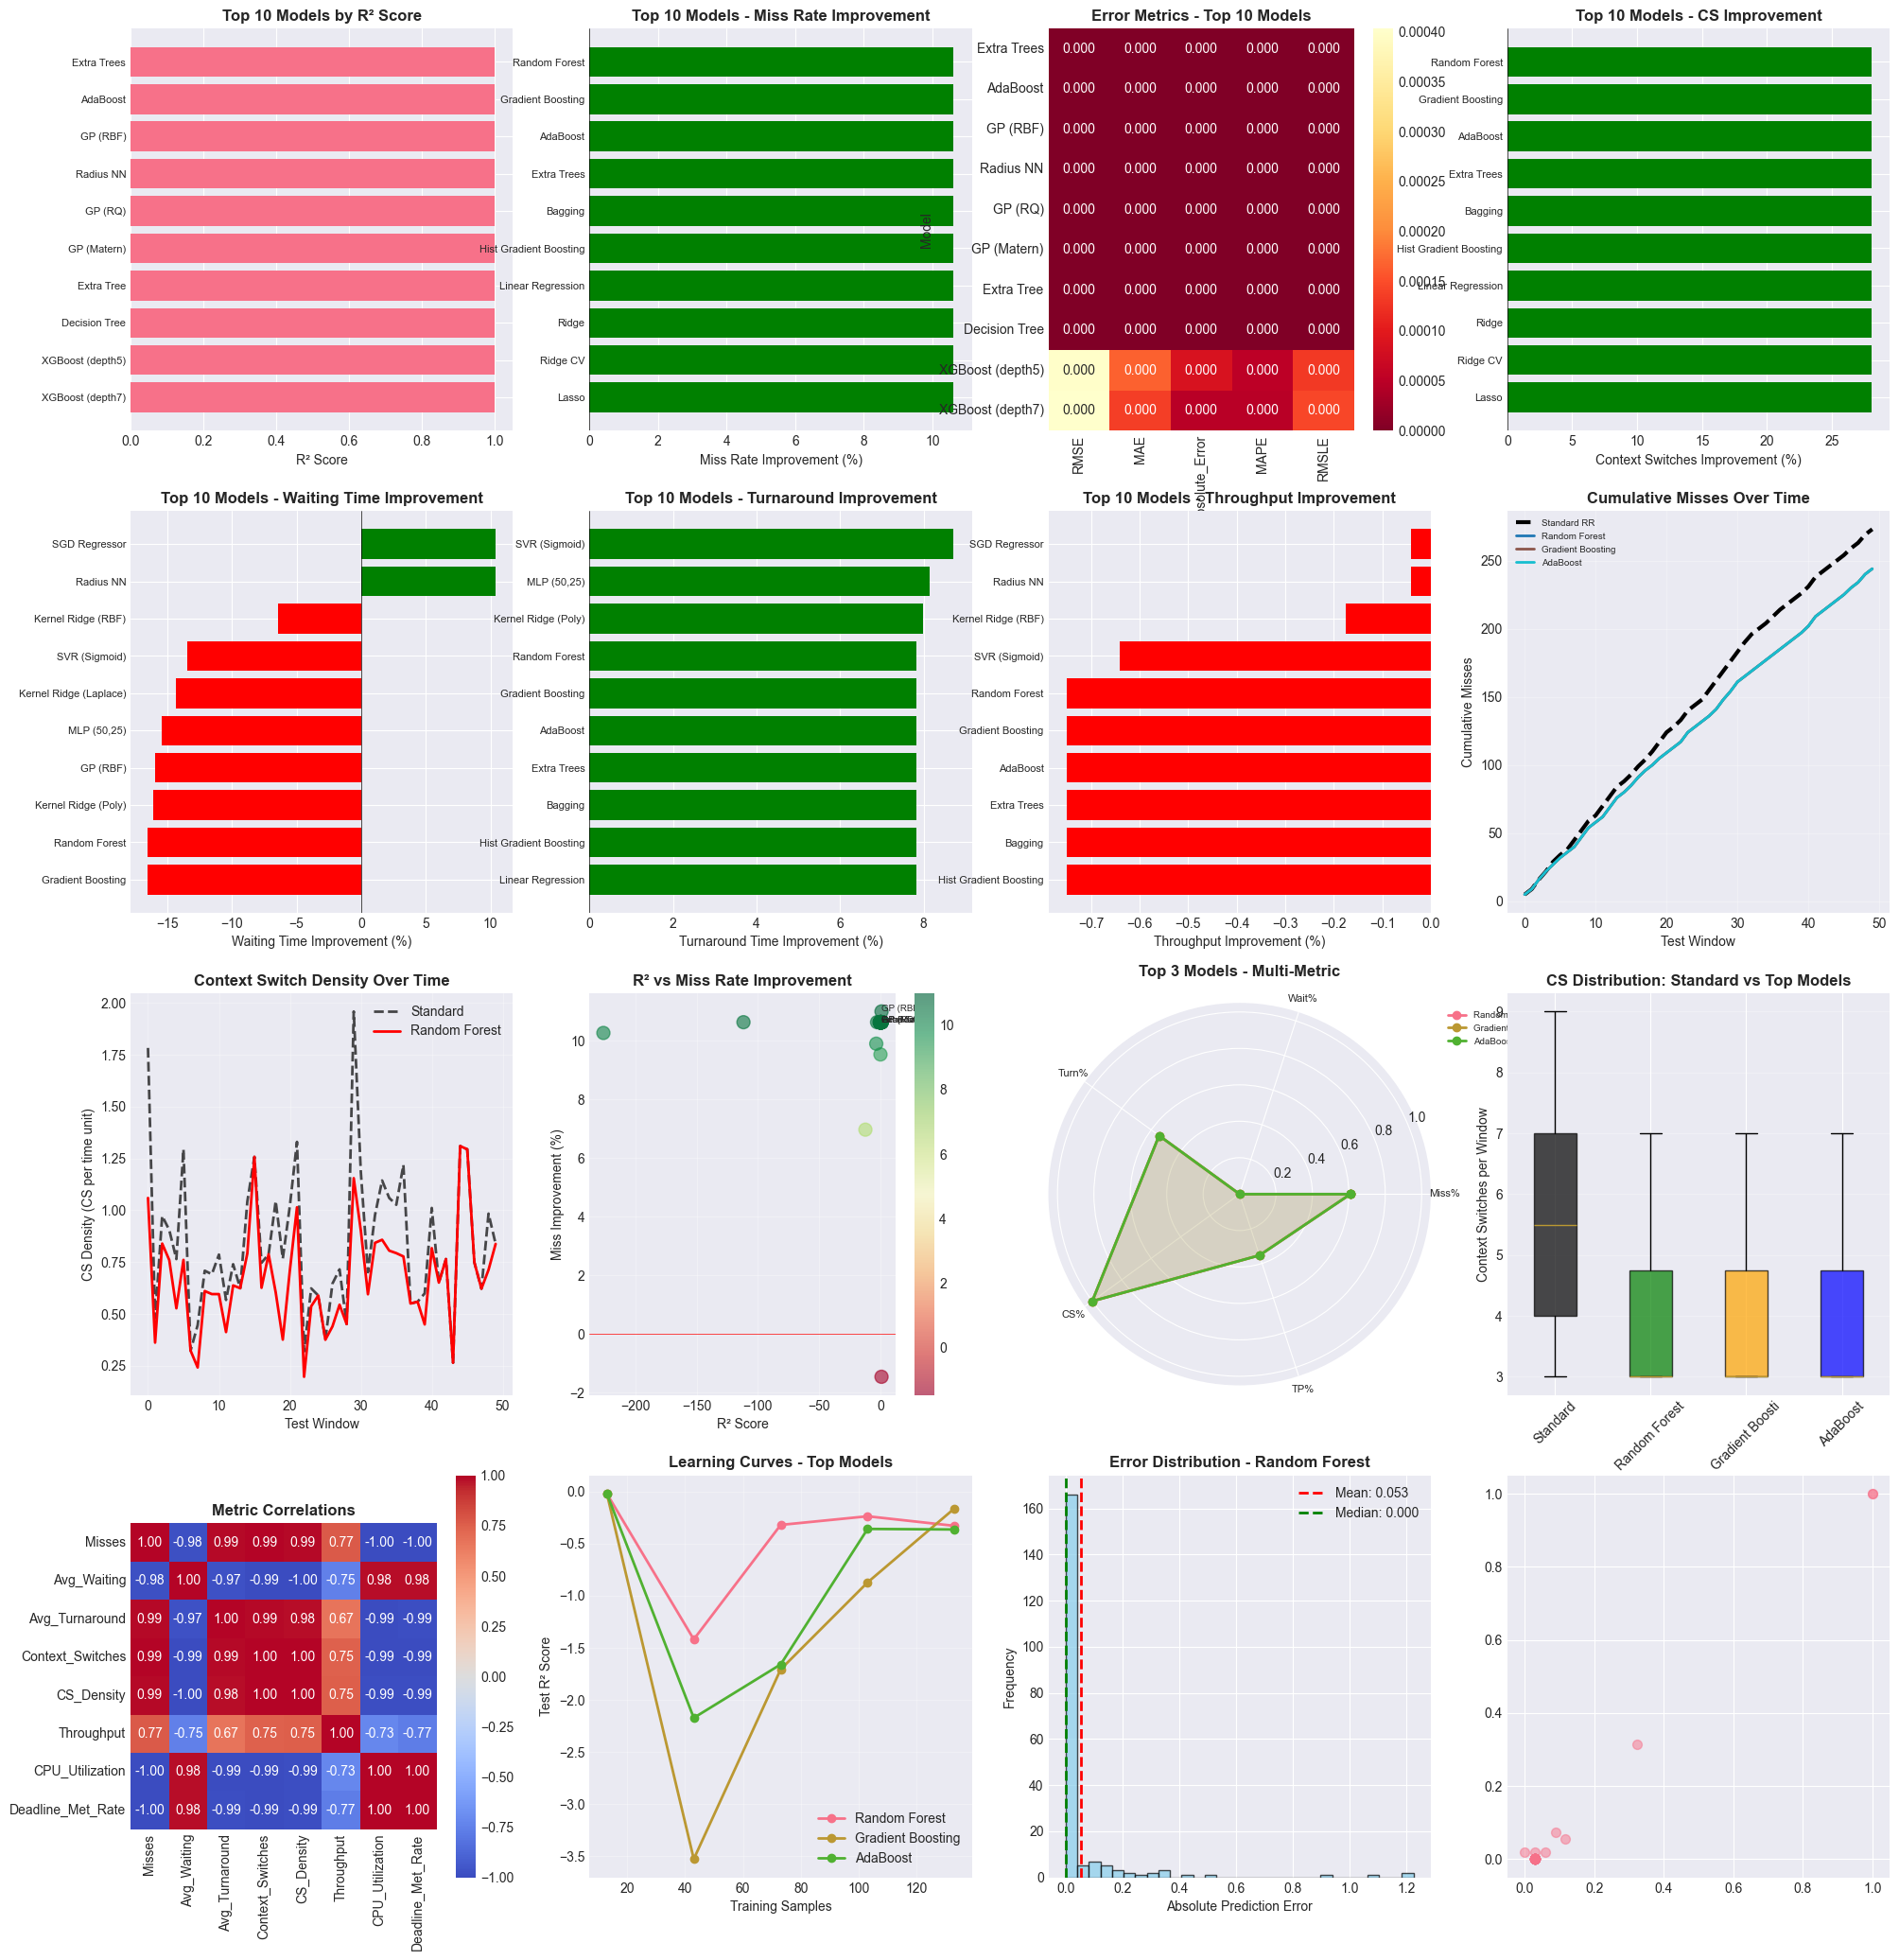

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')
import time
import os
from datetime import datetime
import scipy.stats as stats
from scipy.spatial.distance import cosine
from sklearn.metrics import confusion_matrix, classification_report

# Machine Learning models
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor,
    ExtraTreesRegressor, BaggingRegressor, HistGradientBoostingRegressor
)
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge,
    SGDRegressor, PassiveAggressiveRegressor, HuberRegressor,
    RANSACRegressor, TheilSenRegressor, PoissonRegressor, GammaRegressor,
    TweedieRegressor
)
from sklearn.svm import SVR, LinearSVR, NuSVR
from sklearn.neighbors import KNeighborsRegressor, RadiusNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.cross_decomposition import PLSRegression, CCA
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Additional models
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, WhiteKernel

# Metrics - Comprehensive error metrics
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    explained_variance_score, max_error, mean_absolute_percentage_error,
    median_absolute_error, mean_squared_log_error,
    mean_poisson_deviance, mean_gamma_deviance,
    d2_absolute_error_score, d2_pinball_score, d2_tweedie_score
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.model_selection import cross_val_score, KFold, cross_validate, learning_curve

# ----------------------------
# CONFIGURABLE PARAMETERS
# ----------------------------
N_TRAIN_WINDOWS = 200      # Reduced for speed
N_TEST_WINDOWS = 50        # Keep reasonable for comparison
WINDOW_SIZE = 7            
WINDOW_STEP = 3            
RANDOM_SEED = 42           

# Other configuration
CANDIDATE_SLICES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]
CS_OVERHEAD = 0.05

# Create output directory
OUTPUT_DIR = f"model_comparison_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----------------------------
# 1. Enhanced Simulator with Multiple Metrics
# ----------------------------
class SimulationCache:
    """Cache for simulation results"""
    def __init__(self):
        self.cache = {}
        self.hits = 0
        self.misses = 0
    
    def get_key(self, batch_df, tq):
        key = (batch_df['Job_ID'].iloc[0], batch_df['Arrival_Time'].iloc[0], tq)
        return key
    
    def get(self, batch_df, tq):
        key = self.get_key(batch_df, tq)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        return None
    
    def put(self, batch_df, tq, result):
        key = self.get_key(batch_df, tq)
        self.cache[key] = result

sim_cache = SimulationCache()

def run_detailed_simulation(df_batch, tq, use_cache=True):
    """
    Enhanced simulation that returns multiple metrics:
    - misses: number of deadline misses
    - avg_waiting_time: average waiting time
    - avg_turnaround_time: average turnaround time
    - context_switches: number of context switches
    - additional metrics: max_waiting, response_time, etc.
    """
    if use_cache:
        cached_result = sim_cache.get(df_batch, tq)
        if cached_result is not None:
            return cached_result
    
    time_val = df_batch['Arrival_Time'].min()
    
    # Prepare jobs with additional tracking fields
    jobs = df_batch.copy().rename(columns={'Service_Time': 'bt', 'Deadline_Exp': 'deadline'})
    jobs = jobs.sort_values('Arrival_Time').reset_index(drop=True)
    
    # Add tracking fields
    jobs['original_bt'] = jobs['bt'].copy()
    jobs['completion_time'] = np.nan
    jobs['first_start_time'] = np.nan
    jobs['waiting_time'] = 0
    jobs['turnaround_time'] = 0
    jobs['response_time'] = 0  # Time from arrival to first execution
    jobs['times_preempted'] = 0
    jobs['cs_incurred'] = 0  # Context switches incurred by this job
    
    jobs_list = jobs.to_dict('records')
    
    ready_queue = []
    completed = 0
    misses = 0
    last_pid = None
    context_switches = 0
    total_waiting_time = 0
    completed_jobs = 0
    turnaround_times = []
    waiting_times = []
    response_times = []
    preemptions = []
    cs_per_job = []
    execution_intervals = []  # Track execution intervals for CS pattern analysis
    
    while completed < len(jobs_list) or ready_queue:
        # Move arrived jobs to ready queue
        while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
            new_job = jobs_list.pop(0)
            ready_queue.append(new_job)
        
        if not ready_queue:
            if jobs_list:
                time_val = jobs_list[0]['Arrival_Time']
                continue
            break

        # Sort by Earliest Deadline First (EDF)
        ready_queue.sort(key=lambda x: x['deadline'])
        p = ready_queue.pop(0)

        # Track first start time for waiting/response time calculation
        if pd.isna(p['first_start_time']):
            p['first_start_time'] = time_val
            p['waiting_time'] = time_val - p['Arrival_Time']
            p['response_time'] = time_val - p['Arrival_Time']
            total_waiting_time += p['waiting_time']
            waiting_times.append(p['waiting_time'])
            response_times.append(p['response_time'])

        # Context Switch
        if last_pid is not None and last_pid != p['Job_ID']:
            time_val += CS_OVERHEAD
            context_switches += 1
            p['cs_incurred'] += 1
            execution_intervals.append({
                'time': time_val,
                'from_pid': last_pid,
                'to_pid': p['Job_ID'],
                'type': 'context_switch'
            })
        
        # Execution
        exec_time = min(p['bt'], tq)
        if p['bt'] < tq * 1.1: 
            exec_time = p['bt']
            
        p['bt'] -= exec_time
        time_val += exec_time
        last_pid = p['Job_ID']
        
        execution_intervals.append({
            'time': time_val,
            'pid': p['Job_ID'],
            'duration': exec_time,
            'type': 'execution'
        })

        if p['bt'] <= 0:
            # Job completed
            p['completion_time'] = time_val
            if time_val > p['deadline']:
                misses += 1
            
            # Calculate turnaround time
            turnaround = time_val - p['Arrival_Time']
            turnaround_times.append(turnaround)
            
            completed += 1
            completed_jobs += 1
            preemptions.append(p['times_preempted'])
            cs_per_job.append(p['cs_incurred'])
        else:
            p['times_preempted'] += 1
            # Re-check for arrivals during execution
            while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
                ready_queue.append(jobs_list.pop(0))
            ready_queue.append(p)
    
    # Calculate all metrics
    result = {
        # Miss metrics
        'misses': misses,
        'miss_rate': misses / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        
        # Waiting time metrics
        'avg_waiting_time': np.mean(waiting_times) if waiting_times else 0,
        'median_waiting_time': np.median(waiting_times) if waiting_times else 0,
        'min_waiting_time': np.min(waiting_times) if waiting_times else 0,
        'max_waiting_time': np.max(waiting_times) if waiting_times else 0,
        'std_waiting_time': np.std(waiting_times) if waiting_times else 0,
        'q25_waiting_time': np.percentile(waiting_times, 25) if waiting_times else 0,
        'q75_waiting_time': np.percentile(waiting_times, 75) if waiting_times else 0,
        'iqr_waiting_time': np.percentile(waiting_times, 75) - np.percentile(waiting_times, 25) if waiting_times else 0,
        'skew_waiting_time': stats.skew(waiting_times) if len(waiting_times) > 1 else 0,
        'kurtosis_waiting_time': stats.kurtosis(waiting_times) if len(waiting_times) > 1 else 0,
        
        # Turnaround time metrics
        'avg_turnaround_time': np.mean(turnaround_times) if turnaround_times else 0,
        'median_turnaround_time': np.median(turnaround_times) if turnaround_times else 0,
        'min_turnaround_time': np.min(turnaround_times) if turnaround_times else 0,
        'max_turnaround_time': np.max(turnaround_times) if turnaround_times else 0,
        'std_turnaround_time': np.std(turnaround_times) if turnaround_times else 0,
        'q25_turnaround_time': np.percentile(turnaround_times, 25) if turnaround_times else 0,
        'q75_turnaround_time': np.percentile(turnaround_times, 75) if turnaround_times else 0,
        'iqr_turnaround_time': np.percentile(turnaround_times, 75) - np.percentile(turnaround_times, 25) if turnaround_times else 0,
        
        # Response time metrics
        'avg_response_time': np.mean(response_times) if response_times else 0,
        'median_response_time': np.median(response_times) if response_times else 0,
        'min_response_time': np.min(response_times) if response_times else 0,
        'max_response_time': np.max(response_times) if response_times else 0,
        'std_response_time': np.std(response_times) if response_times else 0,
        
        # Context switch metrics
        'context_switches': context_switches,
        'cs_per_job_avg': np.mean(cs_per_job) if cs_per_job else 0,
        'cs_per_job_max': np.max(cs_per_job) if cs_per_job else 0,
        'cs_per_job_std': np.std(cs_per_job) if cs_per_job else 0,
        'cs_density': context_switches / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        
        # Preemption metrics
        'avg_preemptions': np.mean(preemptions) if preemptions else 0,
        'max_preemptions': np.max(preemptions) if preemptions else 0,
        'total_preemptions': sum(preemptions),
        'preemption_rate': sum(preemptions) / len(df_batch) if len(df_batch) > 0 else 0,
        
        # Throughput and efficiency
        'throughput': completed_jobs / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        'cpu_utilization': sum(df_batch['Service_Time']) / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        'scheduling_overhead': (context_switches * CS_OVERHEAD) / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0,
        
        # Deadline metrics
        'deadline_met_rate': (len(df_batch) - misses) / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        
        # Raw data for further analysis
        'execution_intervals': execution_intervals
    }
    
    if use_cache:
        sim_cache.put(df_batch, tq, result)
    
    return result

def get_real_features(df_batch):
    """Extract features from a batch of jobs"""
    return {
        'avg_service': df_batch['Service_Time'].mean(),
        'arrival_rate': len(df_batch) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'min_deadline': df_batch['Deadline_Exp'].min(),
        'max_deadline': df_batch['Deadline_Exp'].max(),
        'service_std': df_batch['Service_Time'].std(),
        'service_skew': df_batch['Service_Time'].skew(),
        'deadline_range': df_batch['Deadline_Exp'].max() - df_batch['Deadline_Exp'].min(),
        'job_count': len(df_batch),
        'utilization': (df_batch['Service_Time'].sum()) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'deadline_variance': df_batch['Deadline_Exp'].var(),
        'service_quantile_25': df_batch['Service_Time'].quantile(0.25),
        'service_quantile_75': df_batch['Service_Time'].quantile(0.75)
    }

# ----------------------------
# 2. Complete Model Dictionary with Additional Models
# ----------------------------
def get_all_models():
    """Returns ALL ML models with additional variants"""
    models = {
        # Ensemble Methods
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Bagging': BaggingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=RANDOM_SEED),
        
        # Linear Models
        'Linear Regression': LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'Ridge CV': Ridge(alpha=1.0),  # Simplified
        'Lasso': Lasso(alpha=0.01),
        'Lasso CV': Lasso(alpha=0.01),  # Simplified
        'Elastic Net': ElasticNet(alpha=0.01, l1_ratio=0.5),
        'Elastic Net CV': ElasticNet(alpha=0.01, l1_ratio=0.5),  # Simplified
        'Bayesian Ridge': BayesianRidge(),
        'SGD Regressor': SGDRegressor(random_state=RANDOM_SEED, max_iter=1000),
        'Passive Aggressive': PassiveAggressiveRegressor(random_state=RANDOM_SEED),
        'Huber Regressor': HuberRegressor(),
        'RANSAC': RANSACRegressor(random_state=RANDOM_SEED),
        'TheilSen': TheilSenRegressor(random_state=RANDOM_SEED),
        'Poisson': PoissonRegressor(),
        'Gamma': GammaRegressor(),
        'Tweedie': TweedieRegressor(),
        
        # Support Vector Machines
        'SVR (RBF)': SVR(kernel='rbf'),
        'SVR (Linear)': LinearSVR(random_state=RANDOM_SEED, max_iter=1000),
        'SVR (Poly)': SVR(kernel='poly'),
        'SVR (Sigmoid)': SVR(kernel='sigmoid'),
        'NuSVR': NuSVR(),
        
        # Neighbors and Trees
        'KNN (3)': KNeighborsRegressor(n_neighbors=3),
        'KNN (5)': KNeighborsRegressor(n_neighbors=5),
        'KNN (7)': KNeighborsRegressor(n_neighbors=7),
        'KNN (10)': KNeighborsRegressor(n_neighbors=10),
        'Radius NN': RadiusNeighborsRegressor(radius=1.0),
        'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_SEED),
        'Extra Tree': ExtraTreeRegressor(random_state=RANDOM_SEED),
        
        # Neural Networks
        'MLP (50,)': MLPRegressor(hidden_layer_sizes=(50,), random_state=RANDOM_SEED, max_iter=500),
        'MLP (100,)': MLPRegressor(hidden_layer_sizes=(100,), random_state=RANDOM_SEED, max_iter=500),
        'MLP (50,25)': MLPRegressor(hidden_layer_sizes=(50,25), random_state=RANDOM_SEED, max_iter=500),
        'MLP (100,50)': MLPRegressor(hidden_layer_sizes=(100,50), random_state=RANDOM_SEED, max_iter=500),
        
        # Gaussian Processes with different kernels
        'GP (RBF)': GaussianProcessRegressor(kernel=RBF(), random_state=RANDOM_SEED),
        'GP (Matern)': GaussianProcessRegressor(kernel=Matern(), random_state=RANDOM_SEED),
        'GP (RQ)': GaussianProcessRegressor(kernel=RationalQuadratic(), random_state=RANDOM_SEED),
        
        # Kernel Methods
        'Kernel Ridge (RBF)': KernelRidge(kernel='rbf'),
        'Kernel Ridge (Poly)': KernelRidge(kernel='poly'),
        'Kernel Ridge (Laplace)': KernelRidge(kernel='laplacian'),
        
        # Advanced Tree Methods
        'XGBoost (50)': XGBRegressor(n_estimators=50, random_state=RANDOM_SEED),
        'XGBoost (100)': XGBRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'XGBoost (200)': XGBRegressor(n_estimators=200, random_state=RANDOM_SEED),
        'XGBoost (depth3)': XGBRegressor(max_depth=3, random_state=RANDOM_SEED),
        'XGBoost (depth5)': XGBRegressor(max_depth=5, random_state=RANDOM_SEED),
        'XGBoost (depth7)': XGBRegressor(max_depth=7, random_state=RANDOM_SEED),
        
        # Polynomial Features
        'Polynomial (deg 2)': make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
        'Polynomial (deg 3)': make_pipeline(PolynomialFeatures(degree=3), Ridge()),
        'Polynomial (deg 4)': make_pipeline(PolynomialFeatures(degree=4), Ridge(alpha=0.1)),
        
        # Cross Decomposition
        'PLS (2 comp)': PLSRegression(n_components=2),
        'PLS (3 comp)': PLSRegression(n_components=3),
        'PLS (5 comp)': PLSRegression(n_components=5),
        'CCA': CCA(n_components=2),
        
        # Isotonic Regression
        'Isotonic': IsotonicRegression(out_of_bounds='clip'),
        'Isotonic (increasing)': IsotonicRegression(increasing=True, out_of_bounds='clip'),
        'Isotonic (decreasing)': IsotonicRegression(increasing=False, out_of_bounds='clip'),
    }
    
    # Add Voting Ensemble variations
    from sklearn.ensemble import VotingRegressor
    
    # Simple voting
    estimators1 = [
        ('rf', RandomForestRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('gb', GradientBoostingRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('lr', Ridge())
    ]
    models['Voting (RF+GB+LR)'] = VotingRegressor(estimators=estimators1)
    
    # Tree-based voting
    estimators2 = [
        ('rf', RandomForestRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('et', ExtraTreesRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('xgb', XGBRegressor(n_estimators=50, random_state=RANDOM_SEED))
    ]
    models['Voting (RF+ET+XGB)'] = VotingRegressor(estimators=estimators2)
    
    # Linear voting
    estimators3 = [
        ('ridge', Ridge()),
        ('lasso', Lasso(alpha=0.01)),
        ('enet', ElasticNet(alpha=0.01))
    ]
    models['Voting (Ridge+Lasso+EN)'] = VotingRegressor(estimators=estimators3)
    
    return models

# ----------------------------
# 3. Comprehensive Error Metrics Function
# ----------------------------
def calculate_all_error_metrics(y_true, y_pred, model_name=""):
    """Calculate every possible error metric"""
    metrics = {}
    
    # Basic metrics
    metrics['MSE'] = mean_squared_error(y_true, y_pred)
    metrics['RMSE'] = np.sqrt(metrics['MSE'])
    metrics['MAE'] = mean_absolute_error(y_true, y_pred)
    metrics['R2'] = r2_score(y_true, y_pred)
    metrics['Explained_Variance'] = explained_variance_score(y_true, y_pred)
    metrics['Max_Error'] = max_error(y_true, y_pred)
    metrics['Median_Absolute_Error'] = median_absolute_error(y_true, y_pred)
    
    # Percentage errors
    mask = y_true != 0
    if mask.any():
        metrics['MAPE'] = mean_absolute_percentage_error(y_true[mask], y_pred[mask])
        metrics['SMAPE'] = 100 * np.mean(2 * np.abs(y_pred[mask] - y_true[mask]) / (np.abs(y_true[mask]) + np.abs(y_pred[mask])))
    else:
        metrics['MAPE'] = np.nan
        metrics['SMAPE'] = np.nan
    
    # Log errors
    if (y_true >= 0).all() and (y_pred >= 0).all():
        metrics['MSLE'] = mean_squared_log_error(y_true, y_pred)
        metrics['RMSLE'] = np.sqrt(metrics['MSLE'])
    else:
        metrics['MSLE'] = np.nan
        metrics['RMSLE'] = np.nan
    
    # Deviance metrics
    metrics['Poisson_Deviance'] = mean_poisson_deviance(y_true, y_pred)
    metrics['Gamma_Deviance'] = mean_gamma_deviance(y_true, y_pred)
    
    # D2 scores
    metrics['D2_Absolute_Error'] = d2_absolute_error_score(y_true, y_pred)
    metrics['D2_Pinball'] = d2_pinball_score(y_true, y_pred)
    metrics['D2_Tweedie'] = d2_tweedie_score(y_true, y_pred)
    
    # Error distribution metrics
    errors = y_true - y_pred
    abs_errors = np.abs(errors)
    pct_errors = np.abs(errors / (y_true + 1e-10)) * 100
    
    metrics['Mean_Error'] = np.mean(errors)
    metrics['Median_Error'] = np.median(errors)
    metrics['Std_Error'] = np.std(errors)
    metrics['Skew_Error'] = stats.skew(errors) if len(errors) > 1 else 0
    metrics['Kurtosis_Error'] = stats.kurtosis(errors) if len(errors) > 1 else 0
    
    metrics['Mean_Absolute_Error'] = np.mean(abs_errors)
    metrics['Median_Absolute_Error'] = np.median(abs_errors)
    metrics['Std_Absolute_Error'] = np.std(abs_errors)
    
    metrics['Mean_Percentage_Error'] = np.mean(pct_errors)
    metrics['Median_Percentage_Error'] = np.median(pct_errors)
    
    # Quantile errors
    for q in [5, 10, 25, 75, 90, 95]:
        metrics[f'Error_Q{q}'] = np.percentile(errors, q)
        metrics[f'AbsError_Q{q}'] = np.percentile(abs_errors, q)
    
    # Correlation metrics
    metrics['Pearson_Corr'] = np.corrcoef(y_true, y_pred)[0, 1] if len(y_true) > 1 else 0
    metrics['Spearman_Corr'] = stats.spearmanr(y_true, y_pred)[0] if len(y_true) > 1 else 0
    metrics['Kendall_Corr'] = stats.kendalltau(y_true, y_pred)[0] if len(y_true) > 1 else 0
    
    # Distance metrics
    metrics['Cosine_Distance'] = cosine(y_true, y_pred) if len(y_true) > 0 else 0
    metrics['Euclidean_Distance'] = np.sqrt(np.sum((y_true - y_pred) ** 2))
    metrics['Manhattan_Distance'] = np.sum(np.abs(y_true - y_pred))
    
    # Information criteria (simplified)
    n = len(y_true)
    k = 1  # approximate number of parameters
    metrics['AIC'] = n * np.log(metrics['MSE']) + 2 * k if metrics['MSE'] > 0 else np.nan
    metrics['BIC'] = n * np.log(metrics['MSE']) + k * np.log(n) if metrics['MSE'] > 0 else np.nan
    
    # Accuracy metrics (for classification version - if we discretize)
    y_true_class = np.digitize(y_true, bins=CANDIDATE_SLICES)
    y_pred_class = np.digitize(y_pred, bins=CANDIDATE_SLICES)
    
    metrics['Classification_Accuracy'] = accuracy_score(y_true_class, y_pred_class)
    metrics['Precision_Macro'] = precision_score(y_true_class, y_pred_class, average='macro', zero_division=0)
    metrics['Recall_Macro'] = recall_score(y_true_class, y_pred_class, average='macro', zero_division=0)
    metrics['F1_Macro'] = f1_score(y_true_class, y_pred_class, average='macro', zero_division=0)
    
    # Confusion matrix based metrics
    cm = confusion_matrix(y_true_class, y_pred_class, labels=range(len(CANDIDATE_SLICES)))
    if cm.size > 0 and cm.shape[0] == cm.shape[1]:
        metrics['Confusion_Matrix_Diagonal_Sum'] = np.trace(cm)
        metrics['Confusion_Matrix_Off_Diagonal_Sum'] = np.sum(cm) - np.trace(cm)
    
    return metrics

# ----------------------------
# 4. Main Execution
# ----------------------------
if __name__ == "__main__":
    # Set random seed
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    
    start_time = time.time()
    
    print("="*80)
    print("COMPREHENSIVE MODEL COMPARISON WITH ALL METRICS")
    print("="*80)
    print(f"\nConfiguration:")
    print(f"  - Training windows: {N_TRAIN_WINDOWS}")
    print(f"  - Testing windows: {N_TEST_WINDOWS}")
    print(f"  - Window size: {WINDOW_SIZE} jobs")
    print(f"  - Output directory: {OUTPUT_DIR}")
    
    # Load data
    print("\nLoading data...")
    df = pd.read_csv("Kargahi_Movaghar_Source_Data.csv")
    print(f"Dataset shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    
    # Save raw data info
    with open(f"{OUTPUT_DIR}/dataset_info.txt", 'w') as f:
        f.write(f"Dataset: Kargahi_Movaghar_Source_Data.csv\n")
        f.write(f"Shape: {df.shape}\n")
        f.write(f"Columns: {df.columns.tolist()}\n")
        f.write(f"Service Time Stats:\n{df['Service_Time'].describe()}\n")
        f.write(f"Deadline Stats:\n{df['Deadline_Exp'].describe()}\n")
    
    # Generate training data
    print(f"\nStep 1: Generating {N_TRAIN_WINDOWS} training windows...")
    train_data = []
    train_window_details = []
    
    total_possible_indices = list(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
    train_indices = random.sample(total_possible_indices, min(N_TRAIN_WINDOWS, len(total_possible_indices)))
    train_indices.sort()
    
    for i in tqdm(train_indices, desc="Generating training data"):
        batch = df.iloc[i:i+WINDOW_SIZE]
        feats = get_real_features(batch)
        
        # Find best TQ based on misses only (for training target)
        best_tq, min_m = 1.0, float('inf')
        tq_results = {}
        
        for tq_val in CANDIDATE_SLICES:
            result = run_detailed_simulation(batch, tq_val)
            tq_results[tq_val] = result
            if result['misses'] <= min_m:
                min_m, best_tq = result['misses'], tq_val
        
        feats['target_tq'] = best_tq
        feats['window_start_idx'] = i
        train_data.append(feats)
        
        # Store detailed TQ results for this window
        window_detail = {'window_idx': i, 'best_tq': best_tq, 'best_misses': min_m}
        for tq_val in CANDIDATE_SLICES:
            res = tq_results[tq_val]
            window_detail[f'tq_{tq_val}_misses'] = res['misses']
            window_detail[f'tq_{tq_val}_miss_rate'] = res['miss_rate']
            window_detail[f'tq_{tq_val}_waiting'] = res['avg_waiting_time']
            window_detail[f'tq_{tq_val}_turnaround'] = res['avg_turnaround_time']
            window_detail[f'tq_{tq_val}_cs'] = res['context_switches']
            window_detail[f'tq_{tq_val}_cs_density'] = res['cs_density']
            window_detail[f'tq_{tq_val}_throughput'] = res['throughput']
        train_window_details.append(window_detail)
    
    # Prepare training data
    train_df = pd.DataFrame(train_data)
    X = train_df.drop(['target_tq', 'window_start_idx'], axis=1)
    y = train_df['target_tq']
    
    print(f"\nTraining data shape: {X.shape}")
    print(f"Target distribution:\n{y.value_counts().sort_index()}")
    
    # Save training data
    train_df.to_csv(f"{OUTPUT_DIR}/training_data.csv", index=False)
    pd.DataFrame(train_window_details).to_csv(f"{OUTPUT_DIR}/training_window_details.csv", index=False)
    
    # Get all models
    models_dict = get_all_models()
    print(f"\nStep 2: Training {len(models_dict)} ML Models...")
    
    # Train all models and collect comprehensive metrics
    trained_models = {}
    all_error_metrics = []
    prediction_details = []
    learning_curves_data = []
    
    # Cross-validation setup
    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    
    for model_name, model in tqdm(models_dict.items(), desc="Training models"):
        try:
            # Train the model
            model.fit(X, y)
            trained_models[model_name] = model
            
            # Make predictions
            y_pred = model.predict(X)
            
            # Store predictions for each training sample
            for idx, (actual, pred) in enumerate(zip(y, y_pred)):
                prediction_details.append({
                    'model': model_name,
                    'training_sample_idx': idx,
                    'actual_tq': actual,
                    'predicted_tq': pred,
                    'rounded_tq': min(CANDIDATE_SLICES, key=lambda x: abs(x - pred)),
                    'absolute_error': abs(actual - pred),
                    'squared_error': (actual - pred) ** 2,
                    'percentage_error': abs(actual - pred) / (actual + 1e-10) * 100
                })
            
            # Calculate all error metrics
            error_metrics = calculate_all_error_metrics(y, y_pred, model_name)
            error_metrics['Model'] = model_name
            error_metrics['Status'] = 'Success'
            
            # Cross-validation scores
            cv_results = cross_validate(model, X, y, cv=kfold, 
                                       scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error',
                                               'neg_mean_squared_log_error', 'neg_median_absolute_error'],
                                       n_jobs=-1, return_estimator=False)
            
            error_metrics['CV_R2_Mean'] = cv_results['test_r2'].mean()
            error_metrics['CV_R2_Std'] = cv_results['test_r2'].std()
            error_metrics['CV_MSE_Mean'] = -cv_results['test_neg_mean_squared_error'].mean()
            error_metrics['CV_MSE_Std'] = cv_results['test_neg_mean_squared_error'].std()
            error_metrics['CV_MAE_Mean'] = -cv_results['test_neg_mean_absolute_error'].mean()
            error_metrics['CV_MAE_Std'] = cv_results['test_neg_mean_absolute_error'].std()
            
            # Learning curve (sample a few points)
            train_sizes, train_scores, test_scores = learning_curve(
                model, X, y, cv=3, n_jobs=-1, 
                train_sizes=np.linspace(0.1, 1.0, 5),
                scoring='r2'
            )
            
            for size, train_score, test_score in zip(train_sizes, train_scores.mean(axis=1), test_scores.mean(axis=1)):
                learning_curves_data.append({
                    'Model': model_name,
                    'Training_Size': size,
                    'Train_R2': train_score,
                    'Test_R2': test_score
                })
            
            all_error_metrics.append(error_metrics)
            
        except Exception as e:
            print(f"\n⚠️  Error with {model_name}: {str(e)[:50]}")
            all_error_metrics.append({
                'Model': model_name,
                'Status': f'Failed: {str(e)[:50]}',
                'R2': -999
            })
    
    # Convert error metrics to DataFrame
    error_metrics_df = pd.DataFrame(all_error_metrics)
    
    # Sort by R2 (excluding failed models)
    valid_models = error_metrics_df[error_metrics_df['R2'] > -900].copy()
    valid_models = valid_models.sort_values('R2', ascending=False).reset_index(drop=True)
    
    # Save error metrics
    error_metrics_df.to_csv(f"{OUTPUT_DIR}/complete_error_metrics.csv", index=False)
    pd.DataFrame(prediction_details).to_csv(f"{OUTPUT_DIR}/prediction_details.csv", index=False)
    pd.DataFrame(learning_curves_data).to_csv(f"{OUTPUT_DIR}/learning_curves.csv", index=False)
    
    print(f"\nTop 5 Models by R² Score:")
    print(valid_models[['Model', 'R2', 'RMSE', 'MAE', 'MAPE']].head(5).to_string(index=False))
    
    # Step 3: Test on new windows with comprehensive metrics
    print(f"\nStep 3: Testing {len(trained_models)} models on {N_TEST_WINDOWS} windows...")
    
    # Get test indices
    all_indices = set(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
    train_indices_set = set(train_indices)
    available_test_indices = list(all_indices - train_indices_set)
    test_indices = random.sample(available_test_indices, min(N_TEST_WINDOWS, len(available_test_indices)))
    
    # Initialize comprehensive metrics storage
    all_simulation_metrics = []
    cs_pattern_data = []
    
    for idx in tqdm(test_indices, desc="Testing windows"):
        test_batch = df.iloc[idx:idx+WINDOW_SIZE]
        feats_test = pd.DataFrame([get_real_features(test_batch)])
        
        # Test each TQ value (including Standard=0.5)
        for tq_desc, tq_val in [('Standard', 0.5)] + [(f"TQ_{tq}", tq) for tq in CANDIDATE_SLICES]:
            sim_result = run_detailed_simulation(test_batch, tq=tq_val)
            
            # Store simulation metrics
            sim_record = {
                'window_idx': idx,
                'tq_value': tq_val,
                'tq_description': tq_desc,
                **{k: v for k, v in sim_result.items() if k != 'execution_intervals'}
            }
            all_simulation_metrics.append(sim_record)
            
            # Store CS pattern data
            if 'execution_intervals' in sim_result:
                for interval in sim_result['execution_intervals']:
                    cs_pattern_data.append({
                        'window_idx': idx,
                        'tq_value': tq_val,
                        'time': interval['time'],
                        'type': interval['type'],
                        'pid': interval.get('pid', interval.get('to_pid', None)),
                        'from_pid': interval.get('from_pid', None),
                        'to_pid': interval.get('to_pid', None),
                        'duration': interval.get('duration', CS_OVERHEAD)
                    })
        
        # Test each model
        for model_name, model in trained_models.items():
            try:
                pred_tq = float(model.predict(feats_test)[0])
                closest_tq = min(CANDIDATE_SLICES, key=lambda x: abs(x - pred_tq))
                ml_result = run_detailed_simulation(test_batch, tq=closest_tq)
                
                sim_record = {
                    'window_idx': idx,
                    'model_name': model_name,
                    'tq_value': closest_tq,
                    'raw_prediction': pred_tq,
                    **{k: v for k, v in ml_result.items() if k != 'execution_intervals'}
                }
                all_simulation_metrics.append(sim_record)
                
            except Exception as e:
                pass
    
    # Save simulation metrics
    sim_df = pd.DataFrame(all_simulation_metrics)
    sim_df.to_csv(f"{OUTPUT_DIR}/all_simulation_metrics.csv", index=False)
    
    if cs_pattern_data:
        cs_df = pd.DataFrame(cs_pattern_data)
        cs_df.to_csv(f"{OUTPUT_DIR}/context_switch_patterns.csv", index=False)
    
    # Calculate improvements and create comparison dataframe
    std_data = sim_df[sim_df['tq_description'] == 'Standard'].groupby('window_idx').first()
    std_misses = std_data['misses'].sum()
    std_waiting = std_data['avg_waiting_time'].mean()
    std_turnaround = std_data['avg_turnaround_time'].mean()
    std_cs = std_data['context_switches'].sum()
    std_cs_density = std_data['cs_density'].mean()
    std_throughput = std_data['throughput'].mean()
    
    # Aggregate model results
    model_results = []
    for model_name in trained_models.keys():
        model_data = sim_df[sim_df['model_name'] == model_name]
        if len(model_data) > 0:
            model_results.append({
                'Model': model_name,
                'Misses': model_data['misses'].sum(),
                'Miss_Improvement': ((std_misses - model_data['misses'].sum()) / std_misses * 100) if std_misses > 0 else 0,
                'Miss_Rate': model_data['miss_rate'].mean(),
                'Avg_Waiting': model_data['avg_waiting_time'].mean(),
                'Waiting_Improvement': ((std_waiting - model_data['avg_waiting_time'].mean()) / std_waiting * 100) if std_waiting > 0 else 0,
                'Max_Waiting': model_data['max_waiting_time'].max(),
                'Std_Waiting': model_data['std_waiting_time'].mean(),
                'Avg_Turnaround': model_data['avg_turnaround_time'].mean(),
                'Turnaround_Improvement': ((std_turnaround - model_data['avg_turnaround_time'].mean()) / std_turnaround * 100) if std_turnaround > 0 else 0,
                'Max_Turnaround': model_data['max_turnaround_time'].max(),
                'Std_Turnaround': model_data['std_turnaround_time'].mean(),
                'Avg_Response': model_data['avg_response_time'].mean(),
                'Max_Response': model_data['max_response_time'].max(),
                'Context_Switches': model_data['context_switches'].sum(),
                'CS_Improvement': ((std_cs - model_data['context_switches'].sum()) / std_cs * 100) if std_cs > 0 else 0,
                'CS_Density': model_data['cs_density'].mean(),
                'CS_Density_Improvement': ((std_cs_density - model_data['cs_density'].mean()) / std_cs_density * 100) if std_cs_density > 0 else 0,
                'CS_Per_Job': model_data['cs_per_job_avg'].mean(),
                'Avg_Preemptions': model_data['avg_preemptions'].mean(),
                'Total_Preemptions': model_data['total_preemptions'].sum(),
                'Throughput': model_data['throughput'].mean(),
                'Throughput_Improvement': ((model_data['throughput'].mean() - std_throughput) / std_throughput * 100) if std_throughput > 0 else 0,
                'CPU_Utilization': model_data['cpu_utilization'].mean(),
                'Scheduling_Overhead': model_data['scheduling_overhead'].mean(),
                'Deadline_Met_Rate': model_data['deadline_met_rate'].mean()
            })
    
    # Add Standard as baseline
    model_results.insert(0, {
        'Model': 'STANDARD RR (TQ=0.5)',
        'Misses': std_misses,
        'Miss_Improvement': 0,
        'Miss_Rate': std_data['miss_rate'].mean(),
        'Avg_Waiting': std_waiting,
        'Waiting_Improvement': 0,
        'Max_Waiting': std_data['max_waiting_time'].max(),
        'Std_Waiting': std_data['std_waiting_time'].mean(),
        'Avg_Turnaround': std_turnaround,
        'Turnaround_Improvement': 0,
        'Max_Turnaround': std_data['max_turnaround_time'].max(),
        'Std_Turnaround': std_data['std_turnaround_time'].mean(),
        'Avg_Response': std_data['avg_response_time'].mean(),
        'Max_Response': std_data['max_response_time'].max(),
        'Context_Switches': std_cs,
        'CS_Improvement': 0,
        'CS_Density': std_cs_density,
        'CS_Density_Improvement': 0,
        'CS_Per_Job': std_data['cs_per_job_avg'].mean(),
        'Avg_Preemptions': std_data['avg_preemptions'].mean(),
        'Total_Preemptions': std_data['total_preemptions'].sum(),
        'Throughput': std_throughput,
        'Throughput_Improvement': 0,
        'CPU_Utilization': std_data['cpu_utilization'].mean(),
        'Scheduling_Overhead': std_data['scheduling_overhead'].mean(),
        'Deadline_Met_Rate': std_data['deadline_met_rate'].mean()
    })
    
    comparison_df = pd.DataFrame(model_results)
    
    # Merge with error metrics
    complete_report = pd.merge(
        comparison_df,
        valid_models,
        on='Model',
        how='left'
    )
    
    # Save all reports
    comparison_df.to_csv(f"{OUTPUT_DIR}/model_performance_comparison.csv", index=False)
    complete_report.to_csv(f"{OUTPUT_DIR}/complete_report_all_metrics.csv", index=False)
    
    # ----------------------------
    # 5. COMPREHENSIVE VISUALIZATIONS
    # ----------------------------
    print("\nStep 4: Creating comprehensive visualizations...")
    
    # Set style
    plt.style.use('seaborn-v0_8-darkgrid')
    sns.set_palette("husl")
    
    # Create figure with multiple subplots
    fig = plt.figure(figsize=(24, 32))
    
    # 1. Top Models by R² Score
    ax1 = plt.subplot(5, 4, 1)
    top10_r2 = valid_models.head(10)
    bars = ax1.barh(range(len(top10_r2)), top10_r2['R2'])
    ax1.set_yticks(range(len(top10_r2)))
    ax1.set_yticklabels([m[:25] for m in top10_r2['Model']], fontsize=8)
    ax1.set_xlabel('R² Score')
    ax1.set_title('Top 10 Models by R² Score', fontsize=12, fontweight='bold')
    ax1.invert_yaxis()
    
    # 2. Miss Rate Improvement
    ax2 = plt.subplot(5, 4, 2)
    top10_models = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].head(10)
    colors = ['green' if x > 0 else 'red' for x in top10_models['Miss_Improvement']]
    bars = ax2.barh(range(len(top10_models)), top10_models['Miss_Improvement'], color=colors)
    ax2.set_yticks(range(len(top10_models)))
    ax2.set_yticklabels([m[:25] for m in top10_models['Model']], fontsize=8)
    ax2.set_xlabel('Miss Rate Improvement (%)')
    ax2.set_title('Top 10 Models - Miss Rate Improvement', fontsize=12, fontweight='bold')
    ax2.invert_yaxis()
    ax2.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 3. Error Metrics Heatmap
    ax3 = plt.subplot(5, 4, 3)
    heatmap_cols = ['RMSE', 'MAE', 'Median_Absolute_Error', 'MAPE', 'RMSLE']
    available_cols = [col for col in heatmap_cols if col in valid_models.columns]
    heatmap_data = valid_models.head(10)[['Model'] + available_cols].set_index('Model')
    sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlOrRd_r', ax=ax3)
    ax3.set_title('Error Metrics - Top 10 Models', fontsize=12, fontweight='bold')
    
    # 4. Context Switches Improvement
    ax4 = plt.subplot(5, 4, 4)
    top10_cs = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'CS_Improvement')
    colors = ['green' if x > 0 else 'red' for x in top10_cs['CS_Improvement']]
    bars = ax4.barh(range(len(top10_cs)), top10_cs['CS_Improvement'], color=colors)
    ax4.set_yticks(range(len(top10_cs)))
    ax4.set_yticklabels([m[:25] for m in top10_cs['Model']], fontsize=8)
    ax4.set_xlabel('Context Switches Improvement (%)')
    ax4.set_title('Top 10 Models - CS Improvement', fontsize=12, fontweight='bold')
    ax4.invert_yaxis()
    ax4.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 5. Waiting Time Improvement
    ax5 = plt.subplot(5, 4, 5)
    top10_waiting = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Waiting_Improvement')
    colors = ['green' if x > 0 else 'red' for x in top10_waiting['Waiting_Improvement']]
    bars = ax5.barh(range(len(top10_waiting)), top10_waiting['Waiting_Improvement'], color=colors)
    ax5.set_yticks(range(len(top10_waiting)))
    ax5.set_yticklabels([m[:25] for m in top10_waiting['Model']], fontsize=8)
    ax5.set_xlabel('Waiting Time Improvement (%)')
    ax5.set_title('Top 10 Models - Waiting Time Improvement', fontsize=12, fontweight='bold')
    ax5.invert_yaxis()
    ax5.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 6. Turnaround Time Improvement
    ax6 = plt.subplot(5, 4, 6)
    top10_turnaround = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Turnaround_Improvement')
    colors = ['green' if x > 0 else 'red' for x in top10_turnaround['Turnaround_Improvement']]
    bars = ax6.barh(range(len(top10_turnaround)), top10_turnaround['Turnaround_Improvement'], color=colors)
    ax6.set_yticks(range(len(top10_turnaround)))
    ax6.set_yticklabels([m[:25] for m in top10_turnaround['Model']], fontsize=8)
    ax6.set_xlabel('Turnaround Time Improvement (%)')
    ax6.set_title('Top 10 Models - Turnaround Improvement', fontsize=12, fontweight='bold')
    ax6.invert_yaxis()
    ax6.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 7. Throughput Improvement
    ax7 = plt.subplot(5, 4, 7)
    top10_throughput = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Throughput_Improvement')
    colors = ['green' if x > 0 else 'red' for x in top10_throughput['Throughput_Improvement']]
    bars = ax7.barh(range(len(top10_throughput)), top10_throughput['Throughput_Improvement'], color=colors)
    ax7.set_yticks(range(len(top10_throughput)))
    ax7.set_yticklabels([m[:25] for m in top10_throughput['Model']], fontsize=8)
    ax7.set_xlabel('Throughput Improvement (%)')
    ax7.set_title('Top 10 Models - Throughput Improvement', fontsize=12, fontweight='bold')
    ax7.invert_yaxis()
    ax7.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 8. Cumulative Misses (Top 5 vs Standard)
    ax8 = plt.subplot(5, 4, 8)
    
    # Calculate cumulative misses per window
    window_misses = sim_df[sim_df['tq_description'] == 'Standard'].groupby('window_idx')['misses'].sum().cumsum()
    ax8.plot(range(len(window_misses)), window_misses.values, 'k--', linewidth=3, label='Standard RR')
    
    top3_models = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].head(3)['Model'].tolist()
    colors = plt.cm.tab10(np.linspace(0, 1, 3))
    
    for i, model_name in enumerate(top3_models):
        model_misses = sim_df[sim_df['model_name'] == model_name].groupby('window_idx')['misses'].sum()
        if len(model_misses) > 0:
            cum_misses = model_misses.sort_index().cumsum()
            ax8.plot(range(len(cum_misses)), cum_misses.values, label=model_name[:20], linewidth=2, color=colors[i])
    
    ax8.set_xlabel('Test Window')
    ax8.set_ylabel('Cumulative Misses')
    ax8.set_title('Cumulative Misses Over Time', fontsize=12, fontweight='bold')
    ax8.legend(loc='upper left', fontsize=7)
    ax8.grid(True, alpha=0.3)
    
    # 9. CS Density Over Windows
    ax9 = plt.subplot(5, 4, 9)
    
    std_cs_density = sim_df[sim_df['tq_description'] == 'Standard'].groupby('window_idx')['cs_density'].mean()
    ax9.plot(range(len(std_cs_density)), std_cs_density.values, 'k--', linewidth=2, label='Standard', alpha=0.7)
    
    for i, model_name in enumerate(top3_models[:1]):  # Just top model for clarity
        model_cs = sim_df[sim_df['model_name'] == model_name].groupby('window_idx')['cs_density'].mean()
        if len(model_cs) > 0:
            ax9.plot(range(len(model_cs)), model_cs.values, linewidth=2, label=model_name[:20], color='red')
    
    ax9.set_xlabel('Test Window')
    ax9.set_ylabel('CS Density (CS per time unit)')
    ax9.set_title('Context Switch Density Over Time', fontsize=12, fontweight='bold')
    ax9.legend()
    ax9.grid(True, alpha=0.3)
    
    # 10. R² vs Miss Improvement Scatter
    ax10 = plt.subplot(5, 4, 10)
    merged = pd.merge(
        valid_models[['Model', 'R2']],
        comparison_df[['Model', 'Miss_Improvement']],
        on='Model'
    )
    merged = merged[merged['Model'] != 'STANDARD RR (TQ=0.5)']
    
    scatter = ax10.scatter(merged['R2'], merged['Miss_Improvement'], 
                          c=merged['Miss_Improvement'], cmap='RdYlGn', s=100, alpha=0.6)
    
    for _, row in merged.nlargest(5, 'Miss_Improvement').iterrows():
        ax10.annotate(row['Model'][:15], (row['R2'], row['Miss_Improvement']), fontsize=7)
    
    ax10.set_xlabel('R² Score')
    ax10.set_ylabel('Miss Improvement (%)')
    ax10.set_title('R² vs Miss Rate Improvement', fontsize=12, fontweight='bold')
    plt.colorbar(scatter, ax=ax10)
    ax10.axhline(y=0, color='red', linestyle='-', linewidth=0.5)
    ax10.grid(True, alpha=0.3)
    
    # 11. Multi-metric radar (Top 3)
    ax11 = plt.subplot(5, 4, 11, projection='polar')
    metrics_radar = ['Miss_Improvement', 'Waiting_Improvement', 'Turnaround_Improvement', 'CS_Improvement', 'Throughput_Improvement']
    angles = np.linspace(0, 2 * np.pi, len(metrics_radar), endpoint=False).tolist()
    angles += angles[:1]
    
    for i, model_name in enumerate(top3_models):
        model_data = comparison_df[comparison_df['Model'] == model_name].iloc[0]
        values = [model_data[m] for m in metrics_radar]
        # Normalize to 0-1 scale (handle negative values)
        min_val = min(values)
        max_val = max(values)
        if max_val > min_val:
            values = [(v - min_val) / (max_val - min_val) for v in values]
        else:
            values = [0.5] * len(values)
        values += values[:1]
        
        ax11.plot(angles, values, 'o-', linewidth=2, label=model_name[:15])
        ax11.fill(angles, values, alpha=0.1)
    
    ax11.set_xticks(angles[:-1])
    ax11.set_xticklabels(['Miss%', 'Wait%', 'Turn%', 'CS%', 'TP%'], fontsize=8)
    ax11.set_title('Top 3 Models - Multi-Metric', fontsize=12, fontweight='bold', pad=20)
    ax11.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), fontsize=7)
    
    # 12. CS Distribution Box Plot
    ax12 = plt.subplot(5, 4, 12)
    
    box_data = []
    box_labels = ['Standard']
    box_data.append(sim_df[sim_df['tq_description'] == 'Standard']['context_switches'].values)
    
    for model_name in top3_models[:3]:
        model_cs = sim_df[sim_df['model_name'] == model_name]['context_switches'].values
        if len(model_cs) > 0:
            box_data.append(model_cs)
            box_labels.append(model_name[:15])
    
    bp = ax12.boxplot(box_data, patch_artist=True, labels=box_labels)
    colors_box = ['black', 'green', 'orange', 'blue']
    for patch, color in zip(bp['boxes'], colors_box):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax12.set_ylabel('Context Switches per Window')
    ax12.set_title('CS Distribution: Standard vs Top Models', fontsize=12, fontweight='bold')
    ax12.grid(True, alpha=0.3, axis='y')
    ax12.tick_params(axis='x', rotation=45)
    
    # 13. Correlation Heatmap of All Metrics
    ax13 = plt.subplot(5, 4, 13)
    metric_cols = ['Misses', 'Avg_Waiting', 'Avg_Turnaround', 'Context_Switches', 
                   'CS_Density', 'Throughput', 'CPU_Utilization', 'Deadline_Met_Rate']
    available_metrics = [col for col in metric_cols if col in comparison_df.columns]
    corr_data = comparison_df[available_metrics].corr()
    sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax13, square=True)
    ax13.set_title('Metric Correlations', fontsize=12, fontweight='bold')
    
    # 14. Learning Curves (Top 3 Models)
    ax14 = plt.subplot(5, 4, 14)
    
    lc_data = pd.DataFrame(learning_curves_data)
    for model_name in top3_models[:3]:
        model_lc = lc_data[lc_data['Model'] == model_name]
        if len(model_lc) > 0:
            ax14.plot(model_lc['Training_Size'], model_lc['Test_R2'], 'o-', label=model_name[:20], linewidth=2)
    
    ax14.set_xlabel('Training Samples')
    ax14.set_ylabel('Test R² Score')
    ax14.set_title('Learning Curves - Top Models', fontsize=12, fontweight='bold')
    ax14.legend()
    ax14.grid(True, alpha=0.3)
    
    # 15. Error Distribution (Top Model)
    ax15 = plt.subplot(5, 4, 15)
    
    if len(top3_models) > 0:
        top_model = top3_models[0]
        model_errors = [p['absolute_error'] for p in prediction_details if p['model'] == top_model]
        if model_errors:
            ax15.hist(model_errors, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
            ax15.axvline(x=np.mean(model_errors), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(model_errors):.3f}')
            ax15.axvline(x=np.median(model_errors), color='green', linestyle='--', linewidth=2, label=f'Median: {np.median(model_errors):.3f}')
            ax15.set_xlabel('Absolute Prediction Error')
            ax15.set_ylabel('Frequency')
            ax15.set_title(f'Error Distribution - {top_model[:30]}', fontsize=12, fontweight='bold')
            ax15.legend()
    
    # 16. Pareto Frontier (Misses vs CS)
    ax16 = plt.subplot(5, 4, 16)
    
    # Normalize metrics
    plot_data = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].copy()
    plot_data['Norm_Misses'] = (plot_data['Misses'] - plot_data['Misses'].min()) / (plot_data['Misses'].max() - plot_data['Misses'].min() + 1e-10)
    plot_data['Norm_CS'] = (plot_data['Context_Switches'] - plot_data['Context_Switches'].min()) / (plot_data['Context_Switches'].max() - plot_data['Context_Switches'].min() + 1e-10)
    
    # Find Pareto optimal points
    pareto_optimal = []
    for i, row in plot_data.iterrows():
        dominated = False
        for j, other in plot_data.iterrows():
            if i != j:
                if (other['Norm_Misses'] <= row['Norm_Misses'] + 1e-10 and 
                    other['Norm_CS'] <= row['Norm_CS'] + 1e-10 and
                    (other['Norm_Misses'] < row['Norm_Misses'] - 1e-10 or other['Norm_CS'] < row['Norm_CS'] - 1e-10)):
                    dominated = True
                    break
        if not dominated:
            pareto_optimal.append(i)
    
    # Plot
    ax16.scatter(plot_data['Norm_Misses'], plot_data['Norm_CS'], alpha=0.5, label='All Models', s=50)
    
    if pareto_optimal:
        pareto_points = plot_data.iloc[pareto_optimal]
        ax16.scatter(pareto_points['Norm_Misses'], pareto_points['Norm_CS'], 
                    color='red', s=100, marker='s', label='Pareto Optimal', edgecolors='black')
    
    # Add standard point
    std_norm_misses = (std_misses - plot_data['Misses'].min()) / (plot_data['Misses'].max() - plot_data['Misses'].min() + 1e-10)
    std_norm_cs = (std_cs - plot_data['Context_Switches'].min()) / (plot_data['Context_Switches'].max() - plot_data['Context_Switches'].min() + 1e-10)
    
    ax16.scatter(std_norm_misses, std_norm_cs, color='black', s=200, 
                marker='*', label='Standard', edgecolors='white', linewidth=2)
    
    ax16.set_xlabel('Normalized Misses')
    ax16.set_ylabel('Normalized Context Switches')
    ax16.set_title('Pareto: Misses vs Context Switches', fontsize=12, fontweight='bold')
    ax16.legend()
    ax16.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/comprehensive_visualization.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # ----------------------------
    # 6. FINAL REPORT
    # ----------------------------
    print("\n" + "="*80)
    print("FINAL COMPREHENSIVE REPORT")
    print("="*80)
    
    print(f"\n📁 All results saved in: {OUTPUT_DIR}/")
    print("\nFiles generated:")
    files_list = [
        "dataset_info.txt",
        "training_data.csv",
        "training_window_details.csv",
        "complete_error_metrics.csv",
        "prediction_details.csv",
        "learning_curves.csv",
        "all_simulation_metrics.csv",
        "context_switch_patterns.csv",
        "model_performance_comparison.csv",
        "complete_report_all_metrics.csv",
        "comprehensive_visualization.png"
    ]
    
    for f in files_list:
        print(f"  • {f}")
    
    print(f"\n{'='*80}")
    print("TOP 10 MODELS - COMPREHENSIVE COMPARISON")
    print('='*80)
    
    # Display top models with key metrics
    display_cols = ['Model', 'Misses', 'Miss_Improvement', 'Avg_Waiting', 
                   'Avg_Turnaround', 'Context_Switches', 'CS_Improvement',
                   'Throughput', 'R2', 'RMSE', 'MAE']
    
    available_cols = [col for col in display_cols if col in complete_report.columns]
    display_df = complete_report.head(11)[available_cols].round(3)
    
    print(display_df.to_string(index=False))
    
    # Best in each category
    print(f"\n{'='*80}")
    print("BEST IN CATEGORY")
    print('='*80)
    
    categories = {
        'Miss Rate Improvement': ('Miss_Improvement', 'higher'),
        'Waiting Time Improvement': ('Waiting_Improvement', 'higher'),
        'Turnaround Improvement': ('Turnaround_Improvement', 'higher'),
        'Context Switch Improvement': ('CS_Improvement', 'higher'),
        'Throughput Improvement': ('Throughput_Improvement', 'higher'),
        'R² Score': ('R2', 'higher'),
        'Lowest RMSE': ('RMSE', 'lower'),
        'Lowest MAE': ('MAE', 'lower'),
        'Highest Deadline Met Rate': ('Deadline_Met_Rate', 'higher'),
        'Lowest Context Switches': ('Context_Switches', 'lower')
    }
    
    for cat_name, (col, direction) in categories.items():
        if col in complete_report.columns:
            model_data = complete_report[complete_report['Model'] != 'STANDARD RR (TQ=0.5)']
            if len(model_data) > 0:
                if direction == 'higher':
                    best_idx = model_data[col].idxmax()
                else:
                    best_idx = model_data[col].idxmin()
                
                best_model = complete_report.loc[best_idx, 'Model']
                best_value = complete_report.loc[best_idx, col]
                print(f"\n🏆 {cat_name}: {best_model}")
                print(f"   Value: {best_value:.3f}")
    
    print(f"\n{'='*80}")
    print("EXPERIMENT COMPLETE")
    print(f"Total execution time: {time.time() - start_time:.2f} seconds")
    print(f"Total models trained: {len(trained_models)}")
    print(f"Results saved in: {OUTPUT_DIR}/")
    print('='*80)